# Exercise 4: Random Forest Classification

## Objective
Predict bank term-deposit subscriptions using a Random Forest classifier.

## Key Techniques
- Bootstrap aggregation
- Out-of-bag (OOB) evaluation
- Feature importance
- F1-score and classification metrics
- Model comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Load data
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank_marketing.csv"
df = pd.read_csv(DATA_PATH, sep=";")

# Prepare target: handles yes/no or 0/1
y = df["y"].astype(str).str.strip().str.lower().map({
    "no": 0, "yes": 1, "0": 0, "1": 1
})

if y.isna().any():
    raise ValueError(f"Unexpected target values: {df['y'].unique()}")

features = ["age", "job", "duration", "campaign", "poutcome"]
X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["job", "poutcome"]),
    ("num", "passthrough", ["age", "duration", "campaign"])
])

# Random Forest with OOB evaluation
rf_model = Pipeline([
    ("prep", preprocessor),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        oob_score=True,
        bootstrap=True,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("OOB score:", round(rf_model.named_steps["rf"].oob_score_, 4))

print("\nClassification report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

# Feature importance
encoded_names = rf_model.named_steps["prep"].get_feature_names_out()
importances = rf_model.named_steps["rf"].feature_importances_

importance_df = pd.DataFrame({
    "feature": encoded_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print("\nTop 10 features:\n")
print(importance_df.head(10).to_string(index=False))

# Save feature importances and predictions
output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(output_dir / "exercise4_feature_importance.csv", index=False)

predictions = X_test.copy()
predictions["actual_y"] = y_test.to_numpy()
predictions["predicted_y"] = y_pred
predictions["probability"] = y_prob
predictions.to_csv(output_dir / "exercise4_predictions.csv", index=False)

print("\nSaved:")
print("outputs/exercise4_feature_importance.csv")
print("outputs/exercise4_predictions.csv")

c:\Users\bhite\ml-engineering-lab-series-01\.venv\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Accuracy: 0.8659
Precision: 0.4255
Recall: 0.544
F1-score: 0.4775
ROC-AUC: 0.8425
OOB score: 0.8438

Classification report:

              precision    recall  f1-score   support

           0       0.94      0.91      0.92      9137
           1       0.43      0.54      0.48      1160

    accuracy                           0.87     10297
   macro avg       0.68      0.73      0.70     10297
weighted avg       0.88      0.87      0.87     10297


Top 10 features:

                  feature  importance
            num__duration    0.602729
                 num__age    0.193657
            num__campaign    0.054078
    cat__poutcome_success    0.045370
cat__poutcome_nonexistent    0.036491
     cat__job_blue-collar    0.012027
    cat__poutcome_failure    0.009316
         cat__job_student    0.007808
         cat__job_retired    0.006851
          cat__job_admin.    0.005181

Saved:
outputs/exercise4_feature_importance.csv
outputs/exercise4_predictions.csv


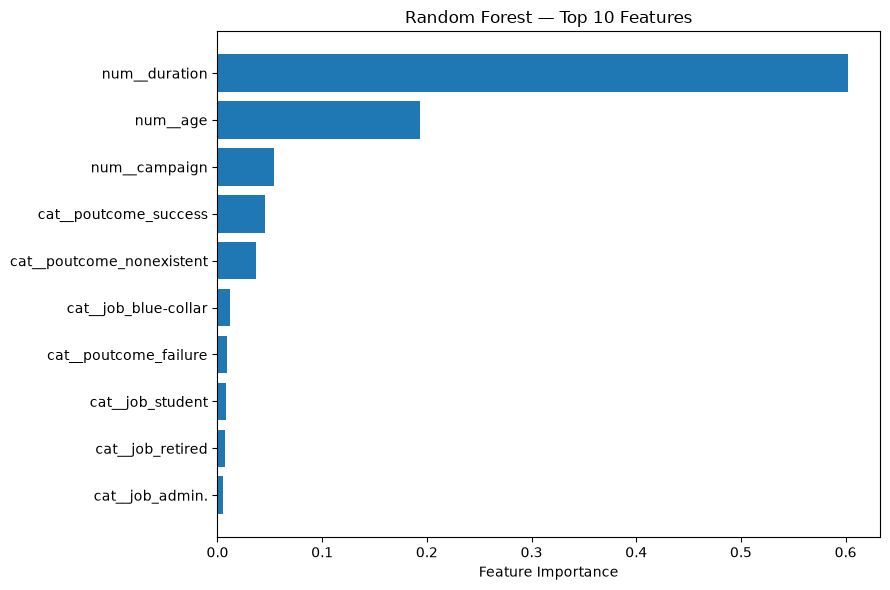

In [2]:
top_features = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.title("Random Forest — Top 10 Features")
plt.tight_layout()
plt.show()